# Try the occupancy study

**Junyu Chen · Chong Li**

Recompute the paper's fixed recommendation comparison from a compact export of 43 saved test horizons. This notebook does not train models or run a building controller. Its core calculations use only Python's standard library; Matplotlib is optional for the figure.

[Research overview](https://stevenchenjy.github.io/decision-aware-occupancy-forecasting/) · [Interactive browser demo](https://stevenchenjy.github.io/decision-aware-occupancy-forecasting/demo/) · [Full reproduction guide](https://github.com/stevenchenjy/decision-aware-occupancy-forecasting/blob/main/REPRODUCING.md)

Use **Run all**. The first cell reads the local checked-in export when available; otherwise it downloads the public JSON from GitHub. No private data or credentials are needed. The export records source SHA-256 hashes so you can identify which records you used.


In [1]:
import json
import math
from pathlib import Path
from urllib.request import urlopen

DEMO_DATA_URL = "https://raw.githubusercontent.com/stevenchenjy/decision-aware-occupancy-forecasting/main/docs/demo/data.json"
local = next((p for p in [Path("docs/demo/data.json"), Path("../docs/demo/data.json")] if p.exists()), None)
if local:
    payload = json.loads(local.read_text())
    print("Data source:", local)
else:
    with urlopen(DEMO_DATA_URL, timeout=30) as response:
        payload = json.load(response)
    print("Data source:", DEMO_DATA_URL)
assert payload["schemaVersion"] == 1
assert len(payload["days"]) == 43
print(payload["scope"])
print(payload["timeConvention"])
for source in payload["sources"]:
    print(source["path"], "SHA-256:", source["sha256"])


Data source: docs/demo/data.json
43 saved, non-overlapping test horizons; 4,128 target intervals
Local Pacific labels. A 00:00 anchor uses the completed 00:00-00:15 input bin; targets span 00:15 to the next 00:15.
results/forecast_predictions_test_all_models.csv SHA-256: f0aa4ff98419a2686a7e393a72c837afdf464e38bea3d650a2da6cdd7f4021be
results/processed_lbnl_15min_pacific.csv SHA-256: b060ce8205f94dfac43194dc185e3d2f56eefcefecf3bf9e625331aba14099a4
results/canonical_policy_10pct.csv SHA-256: a7821c9454584b4e426ae6226acef8825c2f2ce18f41b526ccb8eee891c54dab


## Account for recommendations

An interval is recommended when its uncalibrated Empty score meets the threshold and belongs to a continuous run long enough to meet the duration requirement. Runs stop at each horizon boundary. A conflict means a recommended interval was subsequently camera-labeled occupied. The load proxy sums processed HVAC-plus-lighting load in recommended intervals subsequently camera-labeled empty.

The functions below are copied from `src/demo_analysis.py` so you can inspect and run them without importing the research training environment.


In [2]:
MODELS = {model["id"]: model["label"] for model in payload["models"]}

def stable_mask(scores, threshold, min_steps):
    """Keep whole threshold-passing runs within one horizon, including edges."""
    if not math.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError("Threshold must be finite and between zero and one")
    if not isinstance(min_steps, int) or min_steps < 1:
        raise ValueError("Minimum duration must be a positive number of intervals")
    mask = [False] * len(scores)
    start = None
    for i in range(len(scores) + 1):
        high = i < len(scores) and scores[i] >= threshold
        if high and start is None:
            start = i
        if not high and start is not None:
            if i - start >= min_steps:
                mask[start:i] = [True] * (i - start)
            start = None
    return mask

def evaluate(days, model="hybrid", threshold=0.875, min_steps=4):
    """Account once per target interval, without crossing horizon boundaries."""
    if model not in MODELS:
        raise ValueError(f"Unknown model: {model}")
    recommended = conflicts = windows = 0
    opportunity = []
    for day in days:
        labels, loads, scores = day["empty"], day["loadKwh"], day["scores"][model]
        if len(labels) != len(loads) or len(labels) != len(scores):
            raise ValueError("Scores, labels, and loads must be aligned")
        mask = stable_mask(scores, threshold, min_steps)
        recommended += sum(mask)
        conflicts += sum(on and not label for on, label in zip(mask, labels))
        windows += sum(on and (i == 0 or not mask[i - 1]) for i, on in enumerate(mask))
        opportunity.extend(load for on, label, load in zip(mask, labels, loads) if on and label)
    return {
        "recommendedIntervals": recommended,
        "conflictIntervals": conflicts,
        "recommendedWindows": windows,
        "conflictRate": conflicts / recommended if recommended else 0.0,
        "opportunityKwh": math.fsum(opportunity),
    }


## Reproduce the reported fixed policies

Each model uses its own validation-selected threshold and a one-hour minimum window. All counts below use the same 4,128 unique policy intervals. The manuscript's 388,032 overlapping forecast rows are a different evaluation scope.


In [3]:
reported = []
print(f'{"Model":<22} {"Threshold":>9} {"Windows":>8} {"Intervals":>10} {"Conflicts":>10} {"Load proxy (kWh)":>17}')
for model in payload["models"]:
    result = evaluate(payload["days"], model["id"], model["reportedThreshold"], 4)
    for key, expected in model["reportedMetrics"].items():
        assert math.isclose(result[key], expected, rel_tol=1e-10, abs_tol=1e-7), (model["id"], key)
    reported.append({"model": model["id"], "label": model["label"], **result})
    print(f'{model["label"]:<22} {model["reportedThreshold"]:>9.3f} {result["recommendedWindows"]:>8} {result["recommendedIntervals"]:>10} {result["conflictIntervals"]:>10} {result["opportunityKwh"]:>17.1f}')
hybrid = reported[0]
assert (hybrid["recommendedWindows"], hybrid["recommendedIntervals"], hybrid["conflictIntervals"]) == (14, 259, 0)
assert math.isclose(hybrid["opportunityKwh"], 490.1463795265, abs_tol=1e-7)
print("\nAll three fixed policy rows match the documented comparison.")


Model                  Threshold  Windows  Intervals  Conflicts  Load proxy (kWh)
Selected hybrid            0.875       14        259          0             490.1
Historical schedule        0.950       12         66          0              94.6
LightGBM                   0.950       19        265         11             493.9

All three fixed policy rows match the documented comparison.


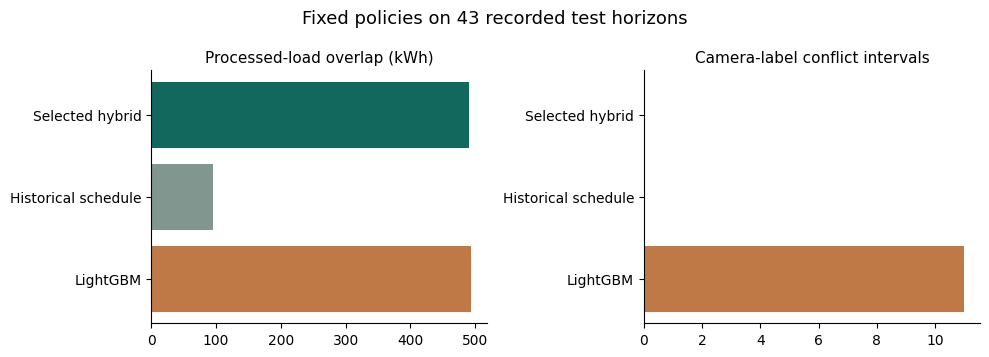

Load overlap is not measured energy savings. Zero recorded conflicts does not guarantee future performance.


In [4]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Optional plot skipped: Matplotlib is not installed. The verified numerical results are above.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    labels = [row["label"] for row in reported]
    colors = ["#13685e", "#80968f", "#bf7947"]
    for ax, key, title in zip(axes, ["opportunityKwh", "conflictIntervals"], ["Processed-load overlap (kWh)", "Camera-label conflict intervals"]):
        ax.barh(labels, [row[key] for row in reported], color=colors)
        ax.invert_yaxis()
        ax.set_title(title, fontsize=11)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle("Fixed policies on 43 recorded test horizons", fontsize=13)
    fig.tight_layout()
    plt.show()
print("Load overlap is not measured energy savings. Zero recorded conflicts does not guarantee future performance.")


## Explore a different setting

Edit the values below and run the cell. This reuses an already inspected test period. It cannot establish a new validated policy or a confirmed improvement. The fixed reported table above remains unchanged.


In [5]:
model_id = "hybrid"     # "hybrid", "historical", or "lightgbm"
threshold = 0.80         # an uncalibrated score cutoff, not an occupancy probability
minimum_hours = 2       # 1, 2, or 4
assert minimum_hours in (1, 2, 4)
exploratory = evaluate(payload["days"], model_id, threshold, minimum_hours * 4)
print("EXPLORATORY REPLAY: no new validation or model selection")
print(json.dumps(exploratory, indent=2))


EXPLORATORY REPLAY: no new validation or model selection
{
  "recommendedIntervals": 451,
  "conflictIntervals": 38,
  "recommendedWindows": 20,
  "conflictRate": 0.08425720620842572,
  "opportunityKwh": 791.29192676125
}


## Share what you actually reproduced

[Open a reproduction report](https://github.com/stevenchenjy/decision-aware-occupancy-forecasting/issues/new?template=reproduction.yml) with the commit or source hashes, environment, commands, and observed outputs. Failed attempts are useful. A successful run here reproduces saved-output accounting; it does not establish independent predictive generalization, operational adoption, energy savings, or verified physical absence.

The input is a cleaned, imputed dataset. Original source timestamp and imputation provenance remain unresolved. Prospective work requires a corrected, protocol-locked empirical rerun and fresh evaluation data. See [the claim limits](https://github.com/stevenchenjy/decision-aware-occupancy-forecasting/blob/main/CLAIMS_AND_LIMITATIONS.md).
